In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error


In [2]:
np.random.seed(0)
X = np.sort(5 * np.random.rand(80, 1), axis=0)


In [4]:
y = np.sin(X).ravel() + np.random.normal(0, 0.5, 80) # Noisy sine wave

In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,
test_size=0.3, random_state=42)

In [8]:
clf = LinearRegression()

In [9]:
clf.fit(X_train , y_train)

LinearRegression()

In [16]:
b = clf.intercept_

In [15]:
m = clf.coef_

In [10]:
y_predict = clf.predict(X_test)

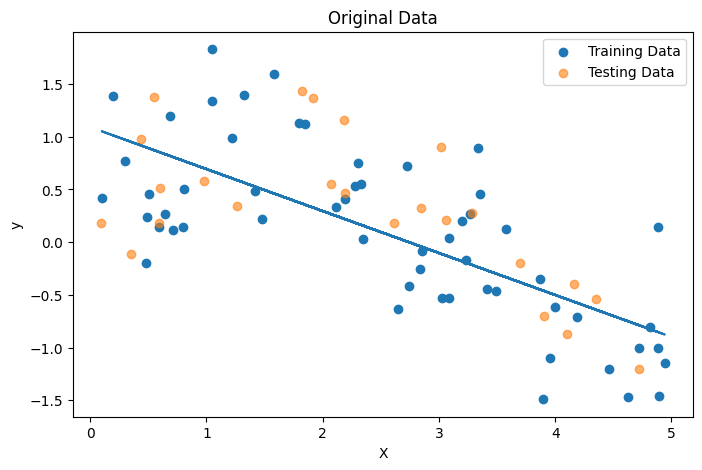

In [17]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, label='Training Data')
plt.scatter(X_test, y_test, label='Testing Data', alpha=0.6)
plt.plot(X_train , m*X_train + b )
plt.title("Original Data")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

In [18]:
# Activity 1.3

In [19]:
model = make_pipeline(
    PolynomialFeatures(degree=20),
    LinearRegression()
)

model.fit(X_train, y_train)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=20)),
                ('linearregression', LinearRegression())])

In [20]:
y_pred = model.predict(X_test)

In [22]:
X_curve = np.linspace(X.min(), X.max(), 500).reshape(-1, 1)
y_curve = model.predict(X_curve)

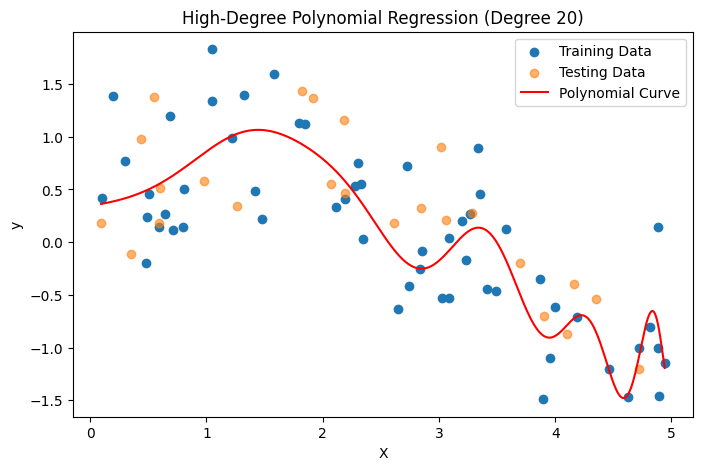

In [23]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, label='Training Data')
plt.scatter(X_test, y_test, label='Testing Data', alpha=0.6)
plt.plot(X_curve, y_curve, color='red', label='Polynomial Curve')
plt.title("High-Degree Polynomial Regression (Degree 20)")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

In [24]:
from sklearn.datasets import make_classification
from sklearn.svm import SVC

In [25]:
X_linear, y_linear = make_classification(n_samples=100,
n_features=2, n_redundant=0, n_informative=2,
n_clusters_per_class=1,
random_state=4, class_sep=1.5)

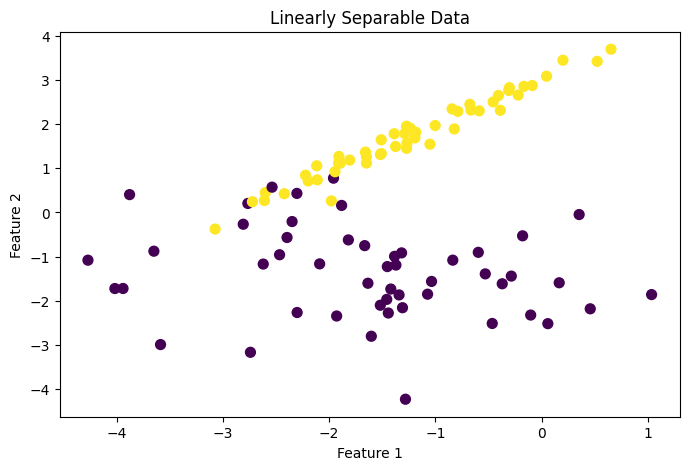

In [26]:
plt.figure(figsize=(8, 5))
plt.scatter(X_linear[:, 0], X_linear[:, 1], c=y_linear,
cmap='viridis', s=50)
plt.title("Linearly Separable Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [27]:
from sklearn.linear_model import LogisticRegression

In [28]:
clf2 = LogisticRegression()

In [29]:
clf2.fit(X_linear ,y_linear )

LogisticRegression()

In [31]:
clf2.coef_

array([[-0.0757154 ,  2.43622282]])

In [32]:
clf2.intercept_

array([-0.79363725])

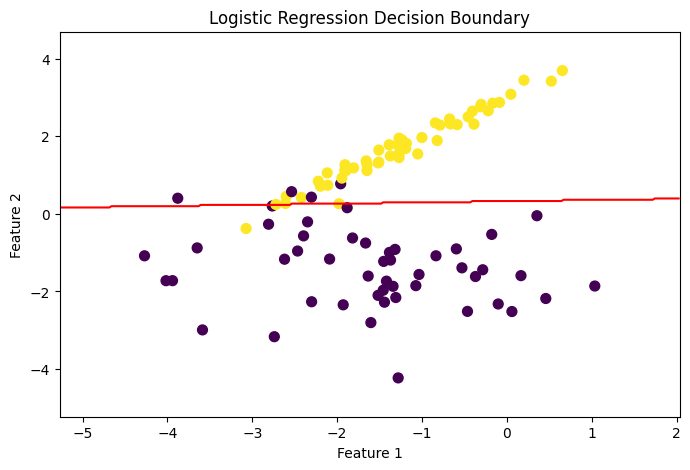

In [33]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    X_linear[:, 0],
    X_linear[:, 1],
    c=y_linear,
    cmap='viridis',
    s=50
)

# Create grid
x_min, x_max = X_linear[:, 0].min() - 1, X_linear[:, 0].max() + 1
y_min, y_max = X_linear[:, 1].min() - 1, X_linear[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Predict on grid
# np.c_ combines arrays column-wise.
grid = np.c_[xx.ravel(), yy.ravel()]
Z = clf2.predict(grid).reshape(xx.shape)

# Plot decision boundary
plt.contour(xx, yy, Z, levels=[0.5], colors='red')

plt.title("Logistic Regression Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [34]:
from sklearn.datasets import make_circles
X_nonlinear, y_nonlinear = make_circles(n_samples=100, noise=0.1,
factor=0.5, random_state=1)

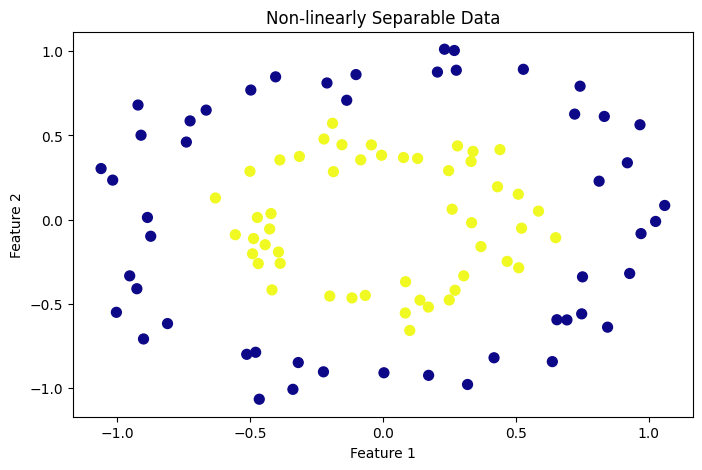

In [36]:
plt.figure(figsize=(8, 5))
plt.scatter(X_nonlinear[:, 0], X_nonlinear[:, 1], c=y_nonlinear,
cmap='plasma', s=50)
plt.title("Non-linearly Separable Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [37]:
clf3 = LogisticRegression()

In [38]:
clf3.fit(X_nonlinear ,y_nonlinear )

LogisticRegression()

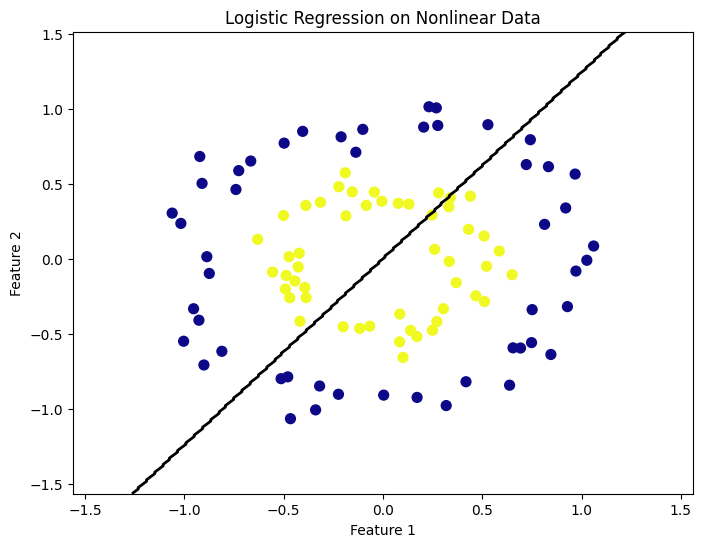

In [39]:
import numpy as np
import matplotlib.pyplot as plt

# Plot original data
plt.figure(figsize=(8, 6))
plt.scatter(X_nonlinear[:, 0], X_nonlinear[:, 1],
            c=y_nonlinear, cmap='plasma', s=50)

# Create grid
x_min, x_max = X_nonlinear[:, 0].min() - 0.5, X_nonlinear[:, 0].max() + 0.5
y_min, y_max = X_nonlinear[:, 1].min() - 0.5, X_nonlinear[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Predict classes over grid
grid = np.c_[xx.ravel(), yy.ravel()]
Z = clf3.predict(grid).reshape(xx.shape)

# Plot decision boundary
plt.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=2)

plt.title("Logistic Regression on Nonlinear Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()